# Soot Modeling Example

_This demo is part of Spitfire, with [licensing and copyright info here.](https://github.com/sandialabs/Spitfire/blob/master/license.md)_


_Highlights_

- Tabulating and plotting soot source term coefficients
- Tabulating and plotting soot radiation and absorption coefficients
- Tabulating and plotting gas radiation and absorption coefficients

In this demo, we build a nonadiabatic flamelet library then add coefficients relevant to soot modeling and absorption/radiation. The different model forms are shown in the soot modeling documentation.



## The nonadiabatic flamelet library
First we'll build a flamelet library for an n-heptane/air system. We are using the liu-C7 mechanism, which limits the soot modeling to Aksit Moss since there is no benzene present. The higher fidelity caltech mechanism incorporates benzene, but takes longer to run.

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from spitfire import build_nonadiabatic_defect_transient_slfm_library, ChemicalMechanismSpec, compute_soot_source_terms
from spitfire import tabulate_gas_radiation_model, tabulate_soot_radiation_model, tabulate_soot_source_coefficients
from spitfire.data.get import datafile


In [16]:
mech = ChemicalMechanismSpec(cantera_input=datafile('liu-C7.yaml'), group_name='gas')
pressure = 101325.
air = mech.stream(stp_air=True)
air.TP = 300., pressure
fuel = mech.stream('TPY', (500., pressure, 'NXC7H16:1'))
flamelet_specs = {'mech_spec': mech,
                  'oxy_stream': air,
                  'fuel_stream': fuel,
                  'grid_points': 81}
chivals = np.logspace(-2,0,2)


In [17]:
lib = build_nonadiabatic_defect_transient_slfm_library(flamelet_specs, chivals)

----------------------------------------------------------------------------------
building nonadiabatic (defect) SLFM library
----------------------------------------------------------------------------------
- mechanism: /ascldap/users/earmstr/.conda/envs/spclone2/lib/python3.11/site-packages/spitfire/data/liu-C7.yaml
- 38 species, 105 reactions
- stoichiometric mixture fraction: 0.062
----------------------------------------------------------------------------------
----------------------------------------------------------------------------------
building adiabatic SLFM library
----------------------------------------------------------------------------------
- mechanism: /ascldap/users/earmstr/.conda/envs/spclone2/lib/python3.11/site-packages/spitfire/data/liu-C7.yaml
- 38 species, 105 reactions
- stoichiometric mixture fraction: 0.062
----------------------------------------------------------------------------------
   1/   2 (chi_stoich =  1.0e-02 1/s)  converged in   2.57 s, T_

## Gas Radiation Model

First we show how to tabulate gas absorption (`gas_abs_coeff`) and radiation (`gas_rad_source`) coefficients. The absorption coefficient has units (1/m) and the radiation coefficient has units (W/m^3).

The default model is `Barlow_GreyGas`, whose equations are outlined in the soot modeling documentation. Below we are plotting the coefficients over mixture fraction and all stoichiometric enthalpy defects for a single stoichiometric dissipation rate.

In [18]:
lib = tabulate_gas_radiation_model(mech, lib, modelname='Barlow_GreyGas')


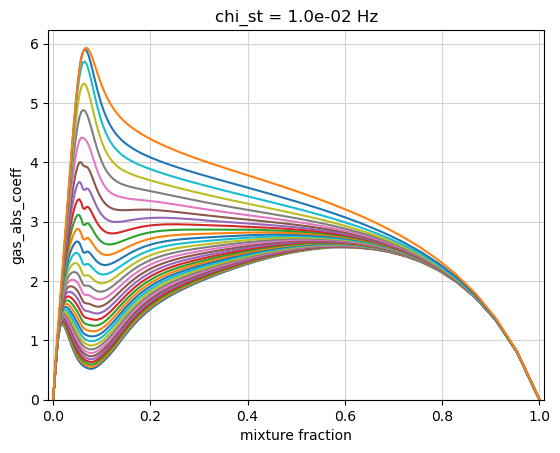

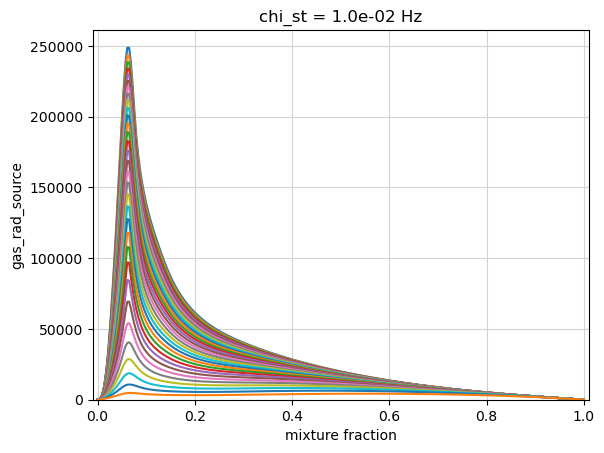

In [19]:
chi_index = 0
for prop in ['gas_abs_coeff','gas_rad_source']:
    plt.plot(lib.mixture_fraction_values, lib[prop][:,chi_index,:])
    plt.grid(color='lightgray')
    plt.ylabel(prop)
    plt.xlabel('mixture fraction')
    plt.title(f'chi_st = {lib.dissipation_rate_stoich_values[chi_index]:.1e} Hz')
    plt.xlim([-0.01,1.01])
    plt.ylim(bottom=0.)
    plt.show()


## Soot Radiation Model

Next we show how to tabulate soot absorption (`soot_abs_coeff`) and radiation (`soot_rad_source`) coefficients. The absorption coefficient has units (1/m) and the radiation coefficient has units (W/m^3).

The default model is `linear_absorption_coefficient`, whose equations are outlined in the soot modeling documentation. This model takes parameters for the linear slope, intercept, and minimum value. Default parameter values are zero, which results in no radiation/absorption. We show suggested values below along with plots of the coefficients over mixture fraction and all stoichiometric enthalpy defects for a single stoichiometric dissipation rate.

In [20]:
lib = tabulate_soot_radiation_model(mech, lib, modelname='linear_absorption_coefficient', input_modelargs={'slope':1735., 'intercept':-3.75e5})


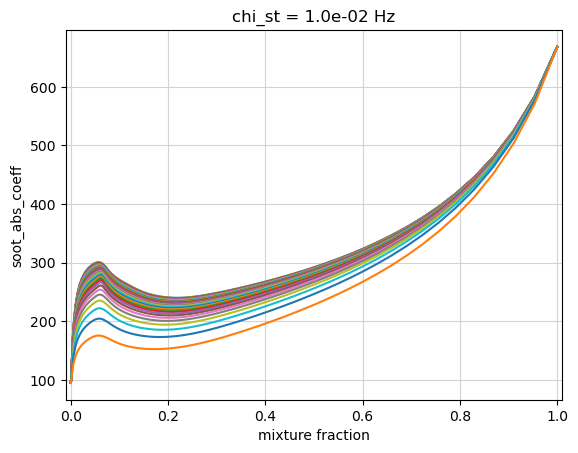

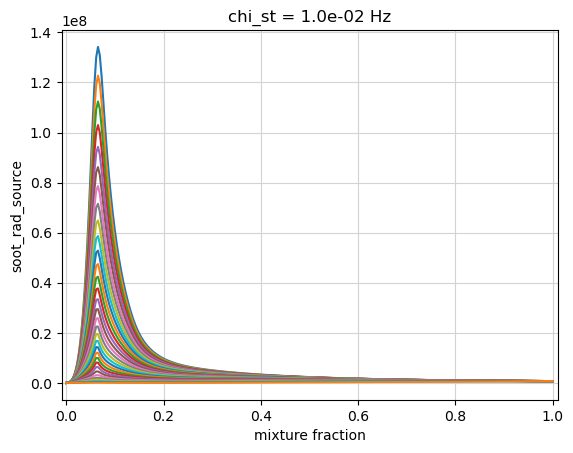

In [21]:
chi_index = 0
for prop in ['soot_abs_coeff','soot_rad_source']:
    plt.plot(lib.mixture_fraction_values, lib[prop][:,chi_index,:])
    plt.grid(color='lightgray')
    plt.ylabel(prop)
    plt.xlabel('mixture fraction')
    plt.title(f'chi_st = {lib.dissipation_rate_stoich_values[chi_index]:.1e} Hz')
    plt.xlim([-0.01,1.01])
    plt.show()


## Soot Source Coefficient Model

Supported soot models include: `Aksit_Moss`, `Aksit_Moss_Benzene`, and `PAH_alpha`. The mechanism we used for this demo does not have benzene, so we will stick with `Aksit_Moss`. All model equations are shown in the soot documentation.

Running `tabulate_soot_source_coefficients` adds relevant coefficients for nucleation, coagulation, condensation, surface growth, and surface oxidation to the library. You can also specify a `percent_soot_leakage` which allows soot to leak into fuel-lean regions of the flame, mimicking a finite-rate oxidation rather than assuming infinitely fast oxidation which does not allow for soot to be present near the oxidizer stream. If the percent leakage is less than 1. (and greater than or equal to 0.), a 'soot_subfilter' property is added showing the function with which the surface growth and oxidation terms get multiplied with.

Below we show plots of the 'Aksit_Moss' coefficients with and without a 1% soot leakage subfilter. The subfilter mainly lowers the oxidation rates as shown below. Units are as follows:
- surface growth and oxidation ('surf_'): kg^(4/3) / m^3 / s / kmol^(1/3)
- nucleation ('nucl_'): kmol / m^3 / s
- coagulation ('coag'): kg^(11/6) / m^3 / s / kmol^(5/6)


In [22]:
soot_model = 'Aksit_Moss'
pct_leakage = 0.01
lib_p0 = tabulate_soot_source_coefficients(mech, lib, soot_model)
lib_p1 = tabulate_soot_source_coefficients(mech, lib, soot_model, pct_leakage)


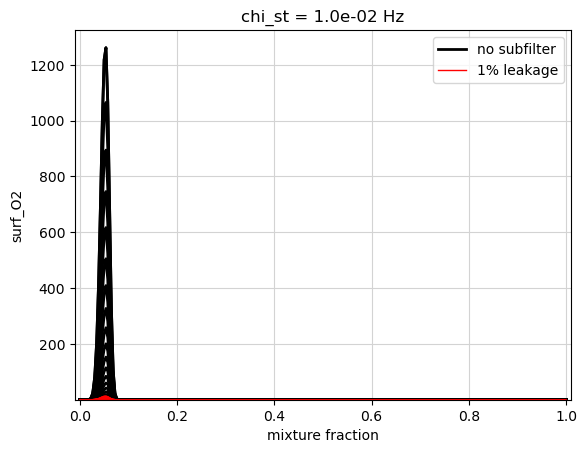

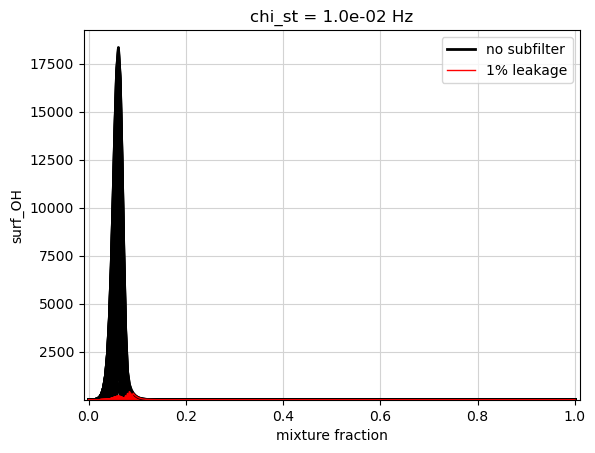

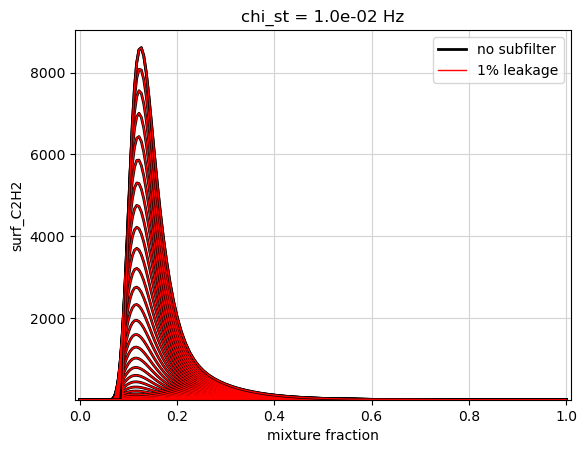

In [23]:
logscale = False
chi_index = 0

colors = ['k','r']
for prop in ['surf_O2', 'surf_OH', 'surf_C2H2']:
    lp0 = lib_p0[prop][:,chi_index,:]
    lp1 = lib_p1[prop][:,chi_index,:]

    plt.plot(lib.mixture_fraction_values, lp0, '-', color=colors[0], linewidth=2)
    plt.plot(lib_p1.mixture_fraction_values, lp1, '-', color=colors[1], linewidth=1)
    #for legend...
    plt.plot(lib.mixture_fraction_values, lp0[:,0], '-', color=colors[0], linewidth=2, label='no subfilter')
    plt.plot(lib_p1.mixture_fraction_values, lp1[:,0], '-', color=colors[1], linewidth=1, label=f'{pct_leakage*100.:.0f}% leakage')

    plt.grid(color='lightgray')
    if logscale:
        plt.yscale('log')
    plt.ylim(bottom=1.e-4)
    plt.title(f'chi_st = {lib.dissipation_rate_stoich_values[chi_index]:.1e} Hz')
    plt.xlim([-0.01,1.01])
    plt.ylabel(prop)
    plt.xlabel('mixture fraction')
    plt.legend()
    plt.show()


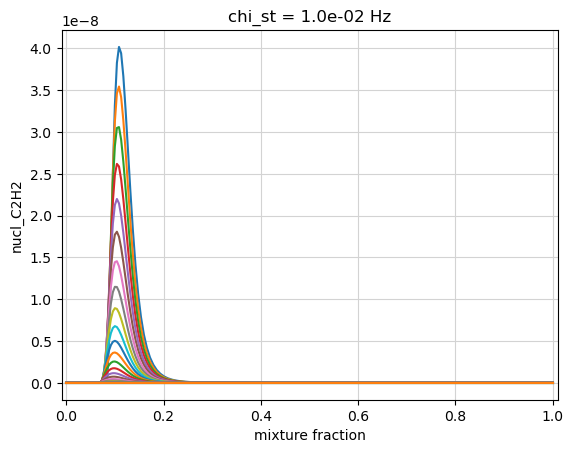

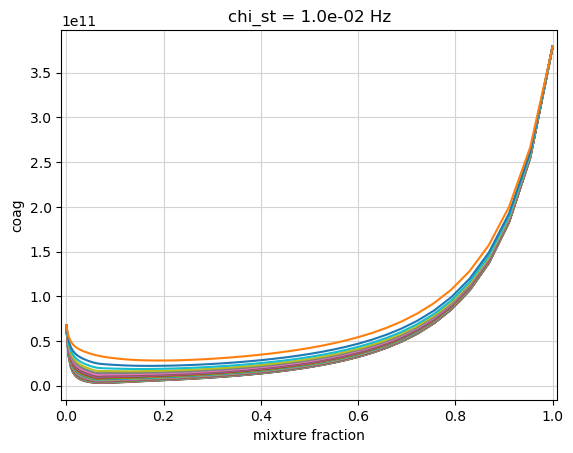

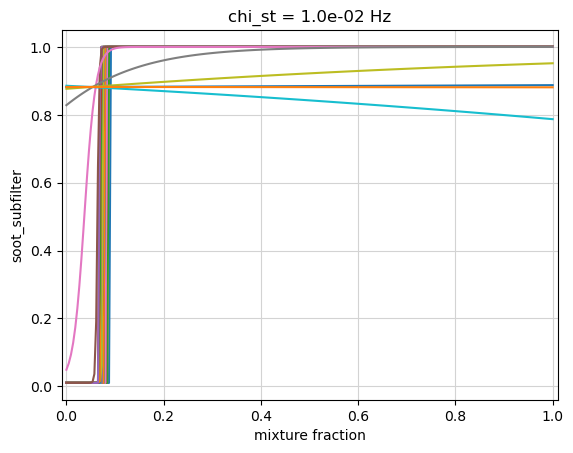

In [24]:
chi_index = 0
for prop in ['nucl_C2H2','coag','soot_subfilter']:
    plt.plot(lib.mixture_fraction_values, lib_p1[prop][:,chi_index,:])
    plt.grid(color='lightgray')
    plt.ylabel(prop)
    plt.xlabel('mixture fraction')
    plt.title(f'chi_st = {lib.dissipation_rate_stoich_values[chi_index]:.1e} Hz')
    plt.xlim([-0.01,1.01])
    plt.show()


## Evaluating Soot Source Terms

Lastly, given a soot number density and mass fraction, the source terms on a library may be evaluated using `compute_soot_source_terms`. The number density is in units (kmol soot / kg air) while the mass fraction is unitless. If verbose is True, the soot model detected on the library will be printed.

The 'clip' argument (default True), ensures that provided number densities remain between 1e-16 and 1e6 and mass fractions remain between 1e-16 and 1. The 'input_mult_dict' argument can be used to set multipliers for any of the source term coefficients on a library. For example, passing {'c2h2':2} will double the surface growth coefficient for acetylene before evaluating the source terms.

Below we plot the source terms for the transport of density-weighted number density and mass fractions (equations shown in the soot modeling documentation). We are plotting over the soot mass fraction for varying values of mixture fraction and soot number density.

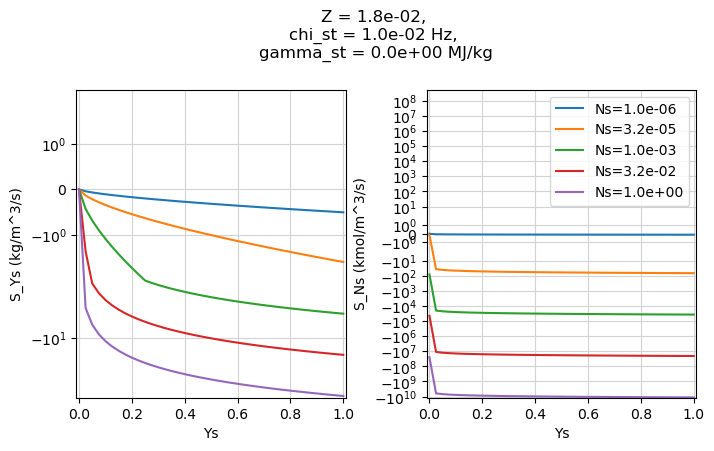

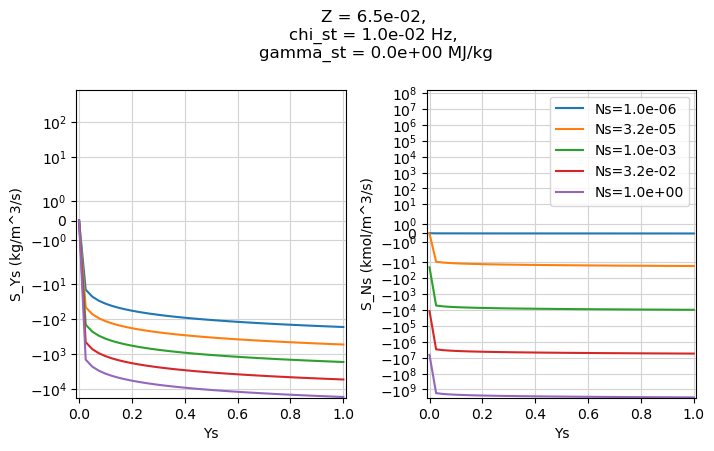

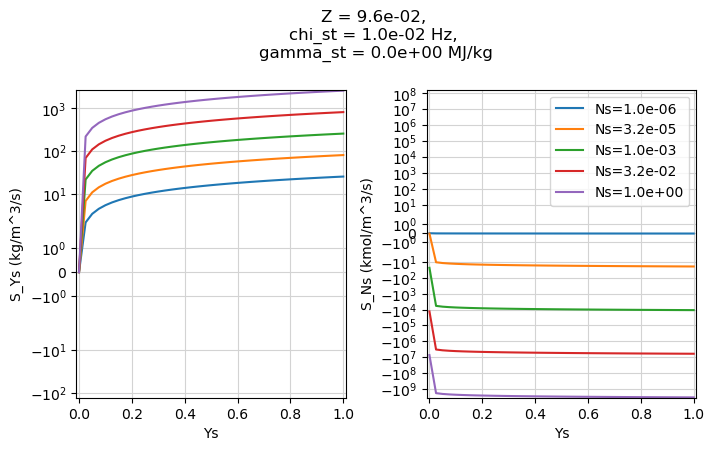

In [25]:
from spitfire import Library, Dimension

Ns = np.logspace(-6,0,5) # soot number density
Ys = np.linspace(0,1,41) # soot mass fraction

zst = mech.stoich_mixture_fraction(fuel, air)
Zs = np.array([zst*0.25, zst, zst*1.5])

# slicing indices for plotting
chi_index = 0
gamma_index = 0

for zs in Zs:
    z_index = np.argmax(lib.mixture_fraction_values - zs>=0)
    fig, (ax1, ax2) = plt.subplots(1,2, figsize=(8,4))

    for nsi, ns in enumerate(Ns):
        lib_Ys = Library(*lib.dims, Dimension('Ys', Ys))
        for prop in ['S_Ns', 'S_Ys']:
            lib_Ys[prop] = lib_Ys.get_empty_dataset()

        for iy, ys in enumerate(Ys):
            src_dict = compute_soot_source_terms(lib_p0, ns, ys, verbose=False)

            lib_Ys['S_Ns'][:,:,:,iy] = src_dict['S_Ns'] # soot number density source term
            lib_Ys['S_Ys'][:,:,:,iy] = src_dict['S_Ys'] # soot mass fraction source term

        ax1.plot(lib_Ys.Ys_values, lib_Ys['S_Ys'][z_index, chi_index, gamma_index, :].T, label=f'Ns={ns:.1e}')
        ax2.plot(lib_Ys.Ys_values, lib_Ys['S_Ns'][z_index, chi_index, gamma_index, :].T, label=f'Ns={ns:.1e}')

    ax1.set_ylabel('S_Ys (kg/m^3/s)')
    ax2.set_ylabel('S_Ns (kmol/m^3/s)')
    plt.suptitle(f'Z = {lib_Ys.mixture_fraction_values[z_index]:.1e}, \nchi_st = {lib_Ys.dissipation_rate_stoich_values[chi_index]:.1e} Hz, \ngamma_st = {lib_Ys.enthalpy_defect_stoich_values[gamma_index]/1.e6:.1e} MJ/kg', y=1.08)
    for ax in [ax1, ax2]:
        ax.set_xlim([-0.01,1.01])
        ax.grid(color='lightgray')
        ax.set_xlabel('Ys')
        ax.set_yscale('symlog')
    plt.legend()
    plt.subplots_adjust(wspace=0.3)
    plt.show()
